# 04 — Perceived authenticity in recipe reviews

**Research question:** *Do the recipes whose ingredients are most typical of their cuisine also get called "authentic" by the people who cook them?*

Simple keyword counts do not work well on recipe reviews: cooks praise authenticity in many ways (*"my Lebanese love said this is the way lentil soup is made"*) while also using authenticity words by accident (*"I used Traditional Ragu sauce"*, *"not authentic"*). We therefore measure perceived authenticity in four steps and compare it with the ingredient scores from `03_network_analysis.ipynb`:

1. **Stage 1 — Word2Vec filter:** expand an authenticity word list on all 132,744 Food.com reviews following Le et al. (2022) and keep only reviews that mention both an authenticity word and a recipe feature in the same sentence.
2. **Stage 2 — Text similarity + wording flags + Logistic Regression:** combine how closely each review matches 6 authenticity descriptions (`gte-small`) with 4 simple wording checks for negation and praise.
3. **Validation & corpus scoring:** test the classifier on hand-labeled reviews (`train_100.csv`, `test_100.csv`) against simpler baselines, then score all 7,281 filtered reviews.
4. **Comparison with the ingredient network:** test whether recipes called authentic also score higher on the ingredient measures from `03_network_analysis.ipynb` using within-cuisine shuffle tests.

## 0. Setup and data

In [1]:
from pathlib import Path
import html
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Resolve repository root whether run from repo root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.authenticity import (
    ANCHOR_THEMES,
    FEATURE_WEIGHTS,
    choose_cutoff,
    classify_title,
    embed_gte,
    fit_cv_classifier,
    kwic_flags,
    shuffle_test,
    summarize_predictions,
)

DATA = ROOT / "data" / "processed"
W2V_DIR = DATA / "recipe_word2vec"
SHARE_DIR = DATA / "authenticity_shareable"
GTE_DIR = ROOT / ".venv" / "share" / "gte-small"
FIG_DIR = ROOT / "figures"

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

recipes = pd.read_csv(DATA / "recipes.csv")
reviews = pd.read_csv(DATA / "reviews.csv")
print(f"Loaded {len(recipes):,} recipes and {len(reviews):,} cleaned reviews across {recipes['cuisine'].nunique()} cuisines.")

Loaded 26,727 recipes and 132,744 cleaned reviews across 9 cuisines.


## 1. Stage 1 — Word2Vec word-list filter

Following Le et al. (2022, *How consumers perceive authenticity in restaurants*), we trained Word2Vec (`scripts/recipe_word2vec.py`) on all 132,744 Food.com reviews to find words used in similar contexts to 88 authenticity seed words and 6 recipe-feature groups (such as dish, ingredient, and preparation). Keeping only reviews where an authenticity word and a recipe feature appear in the same sentence filters out everyday filler like *"a real hit with my kids"*. This narrows the dataset 18× to **7,281 candidate reviews (5.48%)** across **4,295 recipes**.

In [2]:
lexicon = pd.read_csv(W2V_DIR / "lexicon.csv")
neighbors = pd.read_csv(W2V_DIR / "neighbors.csv")
filtered_reviews = pd.read_csv(W2V_DIR / "dictionary_matched_full_reviews.csv")

print("Stage-1 lexicon (seed vs. Word2Vec-added terms):")
display(lexicon.groupby(["category", "source"]).size().unstack(fill_value=0))
print("Top Food.com Word2Vec neighbors of 'authentic':")
display(neighbors.query("seed == 'authentic'").head(6)[["seed", "rank", "neighbor", "cosine"]])
print(f"Stage-1 screen: {len(filtered_reviews):,} reviews ({len(filtered_reviews)/len(reviews):.2%}) "
      f"across {filtered_reviews['recipe_id'].nunique():,} recipes.")

Stage-1 lexicon (seed vs. Word2Vec-added terms):


source,seed,word2vec
category,,
authenticity,88,10
dish,13,57
ingredient,10,33
origin,17,37
preparation,6,19
reference,5,23
sensory,4,18


Top Food.com Word2Vec neighbors of 'authentic':


,seed,rank,neighbor,cosine
42,authentic,1.0,authentically,0.758983
43,authentic,2.0,authenic,0.696370
44,authentic,3.0,comparable,0.687096
45,authentic,4.0,americanized,0.678816
46,authentic,5.0,acquired,0.678674
47,authentic,6.0,genuine,0.655347


Stage-1 screen: 7,281 reviews (5.48%) across 4,295 recipes.


## 2. Stage 2 — Text embeddings, wording flags, and classifier

To tell genuine authenticity praise apart from negations or brand names, we turn each candidate review into **10 simple numbers** and feed them into a **Logistic Regression** classifier (tuned on the training reviews so false alarms stay at or below 10%):

- **6 meaning-similarity scores (`gte-small`):** we use `gte-small`—a compact pretrained language model from the same family as Week 7's MiniLM—to measure how close each review is to 6 short descriptions of authenticity cues from Le et al. (2022, Fig. 1): *connection*, *conformity*, *dish_target*, *affirmation*, *deviation*, and *self_connectedness*.
- **4 clause-level wording flags (KWIC):** splitting each review at punctuation and *"but"*, we check for (1) a positive authenticity word with no negation or change, (2) a negated word (*"not authentic"*), (3) a suggested change (*"more authentic"*, *"instead of"*), and (4) a resemblance phrase (*"just like"*, *"reminds me of"*).

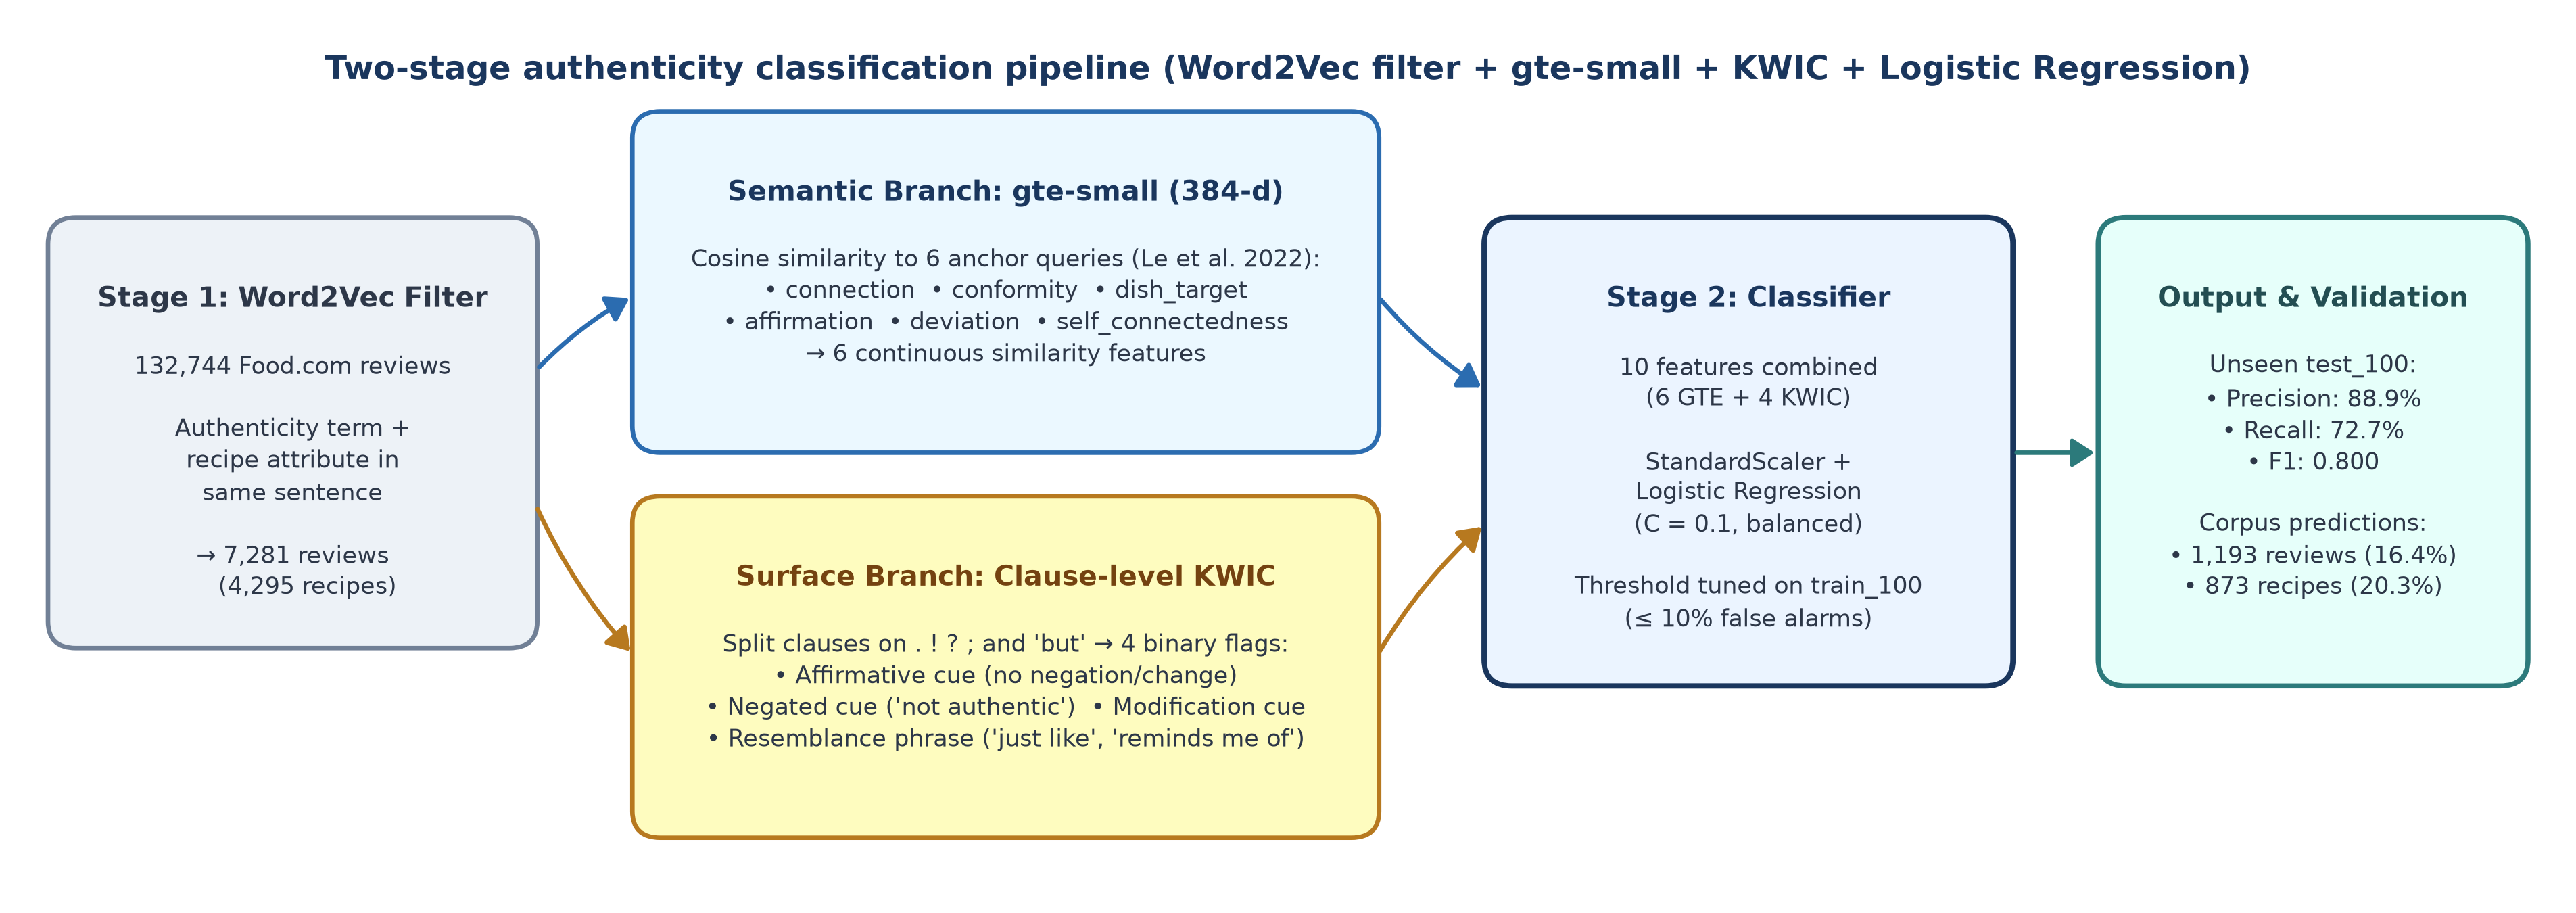

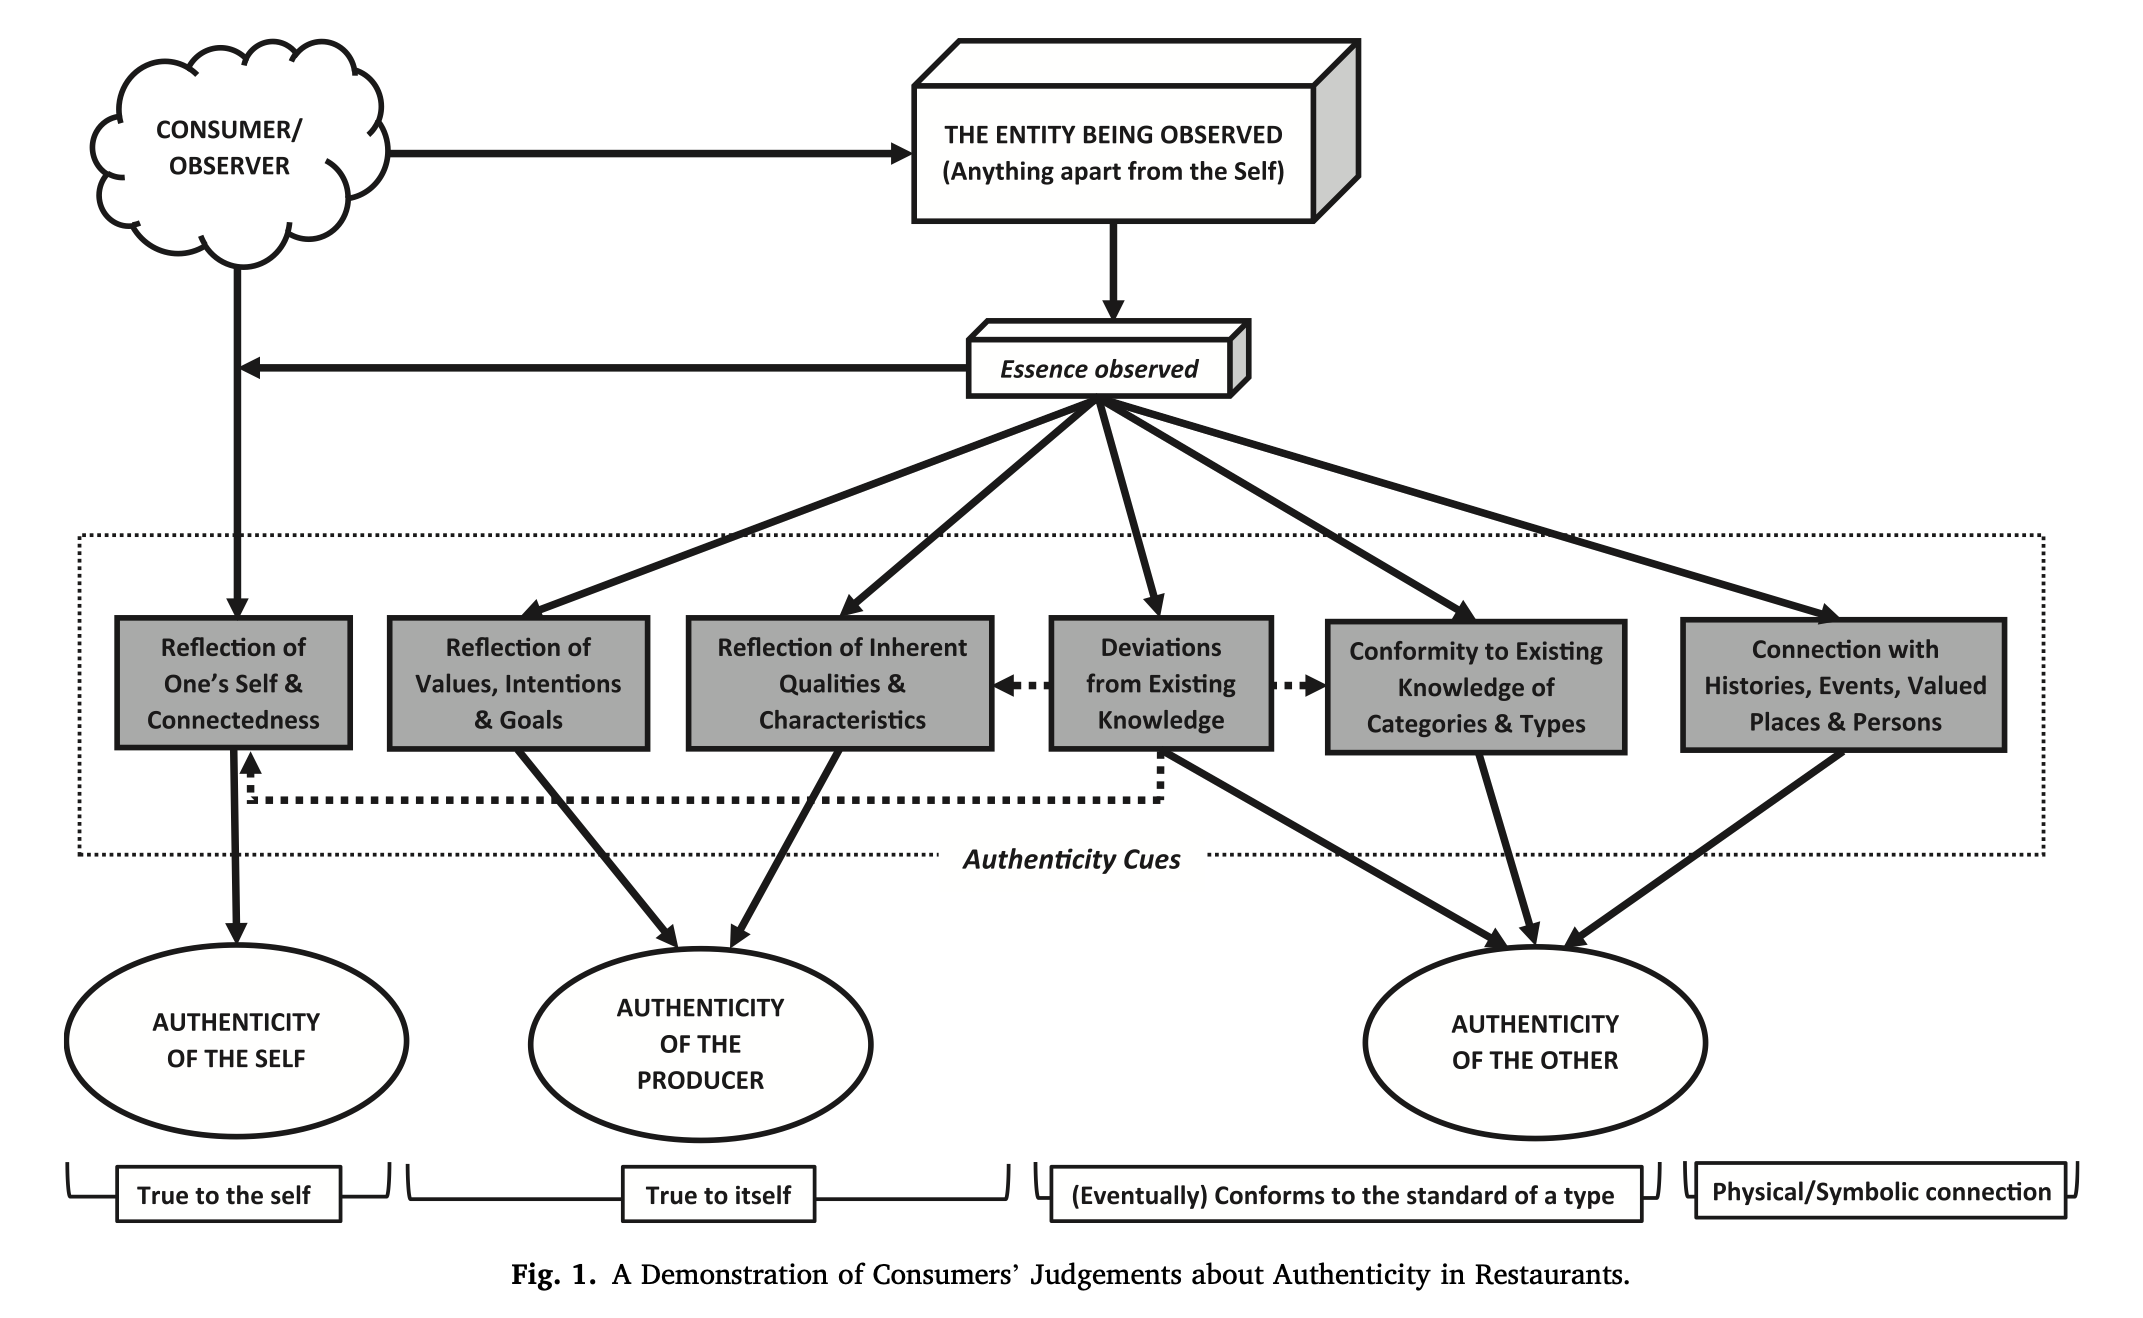

,theme,query
0,connection,This recipe resembles food made by a remembered person or served at a remembered place or event.
1,conformity,The reviewer judges whether the dish matches the expected regional or traditional version.
2,dish_target,"The reviewer judges the posted dish against a family, restaurant or culinary tradition."
3,affirmation,The reviewer confirms that the posted dish matches a remembered or authentic version.
4,deviation,The reviewer describes a departure from the expected dish or traditional way of making it.
5,self_connectedness,"This food connects me with my upbringing, home, identity or family traditions."


In [3]:
pipeline_img = FIG_DIR / "authenticity_pipeline_diagram.png"
if pipeline_img.exists():
    display(Image(filename=str(pipeline_img), width=920))

page8_img = FIG_DIR / "le2022_page8_themes.png"
if page8_img.exists():
    display(Image(filename=str(page8_img), width=760))

pd.set_option("display.max_colwidth", None)
queries = pd.read_csv(W2V_DIR / "gte_single_queries.csv")
selected_queries = queries.set_index("theme").loc[ANCHOR_THEMES].reset_index()
anchor_vectors = embed_gte(selected_queries["query"].tolist(), model_dir=GTE_DIR)
display(selected_queries)

## 3. Validation and baseline comparison

We check how well the classifier works using two separate hand-labeled sets: **`train_100.csv`** (100 reviews, 33 endorsements) and **`test_100.csv`** (100 unseen reviews, 22 endorsements).

**How we pick the yes/no threshold without peeking at `test_100.csv`:**  
We split the 100 training reviews into 5 equal groups of 20 (each with the same share of endorsements) and train the model five times—each time holding out one group of 20 to score it (*5-fold cross-validation*). That gives every training review a realistic score from a model that never saw it. From those scores, we pick the lowest threshold that keeps false alarms at or below 10%. We then train the model once on all 100 training reviews, freeze both the model and that threshold, and test them on the 100 unseen reviews in `test_100.csv`.

Below we compare this full model on `test_100.csv` against simpler alternatives: simple keyword matching, wording flags alone, TF-IDF word counts, `gte-small` similarities alone, and `gte-small` without Logistic Regression.

In [4]:
train_df = pd.read_csv(SHARE_DIR / "train_100.csv")[["recipe_id", "review_id", "full_review", "manual_label"]].copy()
test_df = pd.read_csv(SHARE_DIR / "test_100.csv")[["recipe_id", "review_id", "full_review", "manual_label"]].copy()

X_train = np.column_stack([embed_gte(train_df["full_review"], GTE_DIR) @ anchor_vectors.T, kwic_flags(train_df["full_review"])])
X_test = np.column_stack([embed_gte(test_df["full_review"], GTE_DIR) @ anchor_vectors.T, kwic_flags(test_df["full_review"])])
y_train = train_df["manual_label"].to_numpy(dtype=bool)
y_test = test_df["manual_label"].to_numpy(dtype=bool)

# Full model
scaler, clf, cutoff, oof_scores = fit_cv_classifier(X_train, y_train, weights=FEATURE_WEIGHTS)
test_scores = clf.decision_function(scaler.transform(X_test) * FEATURE_WEIGHTS)
test_pred = test_scores >= cutoff

# Baselines & ablations on the exact same train_100 -> test_100 split
sc_kwic, clf_kwic, cut_kwic, _ = fit_cv_classifier(X_train[:, 6:], y_train)
pred_kwic = clf_kwic.decision_function(sc_kwic.transform(X_test[:, 6:])) >= cut_kwic

sc_gte, clf_gte, cut_gte, _ = fit_cv_classifier(X_train[:, :6], y_train)
pred_gte = clf_gte.decision_function(sc_gte.transform(X_test[:, :6])) >= cut_gte

pos_cols = [0, 1, 2, 3, 5]
zs_tr = X_train[:, pos_cols].mean(axis=1) - X_train[:, 4]
zs_te = X_test[:, pos_cols].mean(axis=1) - X_test[:, 4]
pred_zs = zs_te >= choose_cutoff(y_train, zs_tr)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")
clf_tfidf = LogisticRegression(class_weight="balanced", max_iter=2000).fit(tfidf.fit_transform(train_df["full_review"]), y_train)
pred_tfidf = clf_tfidf.predict(tfidf.transform(test_df["full_review"]))

pred_dict = test_df["full_review"].str.contains(r"\b(?:authentic\w*|traditional\w*|genuine)\b", case=False, regex=True).to_numpy()

print(f"Decision threshold tuned on train_100 (<=10% false alarms): {cutoff:.3f}")
eval_table = pd.DataFrame([
    summarize_predictions("Full model — train_100 (5-fold cross-validation)", y_train, oof_scores >= cutoff),
    summarize_predictions("Full model — test_100 (GTE + wording flags + LR)", y_test, test_pred),
    summarize_predictions("Without wording flags (GTE + LR)", y_test, pred_gte),
    summarize_predictions("Without GTE (wording flags + LR)", y_test, pred_kwic),
    summarize_predictions("Without Logistic Regression (GTE only)", y_test, pred_zs),
    summarize_predictions("Baseline — TF-IDF word counts + LR", y_test, pred_tfidf),
    summarize_predictions("Baseline — Simple keyword match", y_test, pred_dict),
])
display(eval_table)

# Compact illustrative examples from test_100
test_df["pred"] = test_pred
examples = pd.concat([
    test_df[test_df["manual_label"] & test_df["pred"]].head(2),
    test_df[~test_df["manual_label"] & ~test_df["pred"]].head(2),
])[["recipe_id", "manual_label", "pred", "full_review"]].copy()
examples["full_review"] = examples["full_review"].map(lambda s: " ".join(html.unescape(s).split())[:150] + "...")
print("\nSample held-out test_100 reviews:")
display(examples)

Decision threshold tuned on train_100 (<=10% false alarms): 0.699


,variant,TP,FP,FN,TN,precision,recall,F1
0,Full model — train_100 (5-fold cross-validation),20,6,13,61,0.769,0.606,0.678
1,Full model — test_100 (GTE + wording flags + LR),16,2,6,76,0.889,0.727,0.800
2,Without wording flags (GTE + LR),9,3,13,75,0.750,0.409,0.529
3,Without GTE (wording flags + LR),16,3,6,75,0.842,0.727,0.780
4,Without Logistic Regression (GTE only),4,10,18,68,0.286,0.182,0.222
5,Baseline — TF-IDF word counts + LR,8,3,14,75,0.727,0.364,0.485
6,Baseline — Simple keyword match,17,12,5,66,0.586,0.773,0.667



Sample held-out test_100 reviews:


,recipe_id,manual_label,pred,full_review
0,166030,1,True,The perfect mixture for that traditional taco taste. No need to buy that packaged stuff. I used it for recipe #160564 and it was great. Thanks for sha...
1,47453,1,True,Thank you for putting up an authentic recipe!...
2,8745,0,False,wonderful I Dont' think i will ever make original enchiladas again. We are died in the wool Texans so everyone turned tier noses up when I said velvee...
3,31717,0,False,"I halved this recipe for my smaller crock pot. I also veganized it (using tvp for the ground beef and made my own veggie ""beefish"" broth) We gobbled i..."


## 4. Perceived authenticity across Food.com recipes

On the 100 unseen test reviews, the full model reaches **88.9% precision (16/18)** and **72.7% recall (16/22; F1 = 0.800)**, beating every simpler alternative. Next we run it on all **7,281** Stage-1 candidate reviews (using precomputed `gte-small` vectors for speed) and mark a recipe as endorsed if at least one of its reviews is classified as an endorsement.

Reviews classified: 7,281 -> 1,193 endorsed (16.4%)
Recipes covered:    4,295 -> 873 endorsed (20.3%)


,matched_reviews,endorsed_reviews,matched_recipes,review_endorsement_rate
cuisine,,,,
japanese,190,42,130,0.221
greek,564,123,345,0.218
middle-eastern,476,97,342,0.204
indian,559,113,388,0.202
chinese,517,102,293,0.197
thai,302,51,205,0.169
mexican,2028,330,1142,0.163
italian,2224,296,1151,0.133
french,421,39,299,0.093


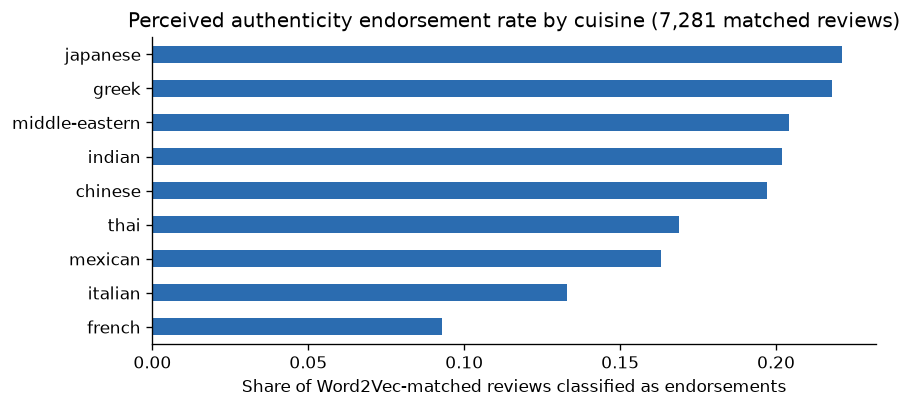

In [5]:
pred_reviews = filtered_reviews.copy()
cache_path = W2V_DIR / "gte_dictionary_review_vectors.npz"
if cache_path.exists():
    with np.load(cache_path) as cache:
        idx = pd.Index(cache["ids"]).get_indexer(pred_reviews["review_id"])
        assert (idx >= 0).all()
        all_review_vecs = cache["vectors"][idx].astype(np.float32)
else:
    all_review_vecs = embed_gte(pred_reviews["full_review"].tolist(), model_dir=GTE_DIR, batch_size=64)

X_all = np.column_stack([all_review_vecs @ anchor_vectors.T, kwic_flags(pred_reviews["full_review"])])
pred_reviews["score"] = clf.decision_function(scaler.transform(X_all) * FEATURE_WEIGHTS)
pred_reviews["predicted_endorsement"] = pred_reviews["score"] >= cutoff

n_pos_rev = int(pred_reviews["predicted_endorsement"].sum())
n_pos_rec = int(pred_reviews.loc[pred_reviews["predicted_endorsement"], "recipe_id"].nunique())
n_tot_rec = int(pred_reviews["recipe_id"].nunique())

print(f"Reviews classified: {len(pred_reviews):,} -> {n_pos_rev:,} endorsed ({n_pos_rev/len(pred_reviews):.1%})")
print(f"Recipes covered:    {n_tot_rec:,} -> {n_pos_rec:,} endorsed ({n_pos_rec/n_tot_rec:.1%})")

by_cuisine = (
    pred_reviews.groupby("cuisine")
    .agg(matched_reviews=("review_id", "size"), endorsed_reviews=("predicted_endorsement", "sum"), matched_recipes=("recipe_id", "nunique"))
    .assign(review_endorsement_rate=lambda d: (d["endorsed_reviews"] / d["matched_reviews"]).round(3))
    .sort_values("review_endorsement_rate", ascending=False)
)
display(by_cuisine)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
by_cuisine["review_endorsement_rate"].sort_values().plot.barh(ax=ax, color="#2b6cb0")
ax.set_xlabel("Share of Word2Vec-matched reviews classified as endorsements")
ax.set_ylabel("")
ax.set_title("Perceived authenticity endorsement rate by cuisine (7,281 matched reviews)")
plt.tight_layout()
plt.show()

## 5. Linking perceived authenticity to ingredient distinctiveness

In `03_network_analysis.ipynb`, we built the recipe–ingredient network and gave each recipe three scores capturing different aspects of how typical its ingredients are (saved in `network_recipe_distinctiveness_full.csv`):
- **`ingredient_distinctiveness`** (*what*): how typical the recipe's single ingredients are of its cuisine (Ahn et al., 2011).
- **`pair_distinctiveness`** (*which*): how typical its ingredient pairs are—which can still be high simply because two popular ingredients appear in the same cuisine.
- **`pairing_score`** (*how*): how much more typical the recipe's ingredient pairs are *compared to a randomized null network* from `03_network_analysis.ipynb` that keeps every recipe's length and every ingredient's popularity fixed. This isolates recipes whose ingredients are specifically paired together rather than just individually common.

To see whether reviewers' endorsements agree with these ingredient scores, we first divide each cuisine's recipes into four equal groups (quartiles, from lowest 25% to highest 25% of `pairing_score`) and compare how often each group is called authentic. Next, we compute **Spearman's rank correlation (ρ)** inside each cuisine—a simple measure of whether recipes ranked higher on `pairing_score` are also more likely to be called authentic.

,pairing_q,recipes,endorsed,endorsement_rate
0,Q1 (lowest 25%),1073,165,15.4%
1,Q2,1067,192,18.0%
2,Q3,1067,228,21.4%
3,Q4 (highest 25%),1068,287,26.9%


Bottom 10% vs. Top 10% of pairing_score: 13.9% -> 26.0% (1.87x higher endorsement rate)


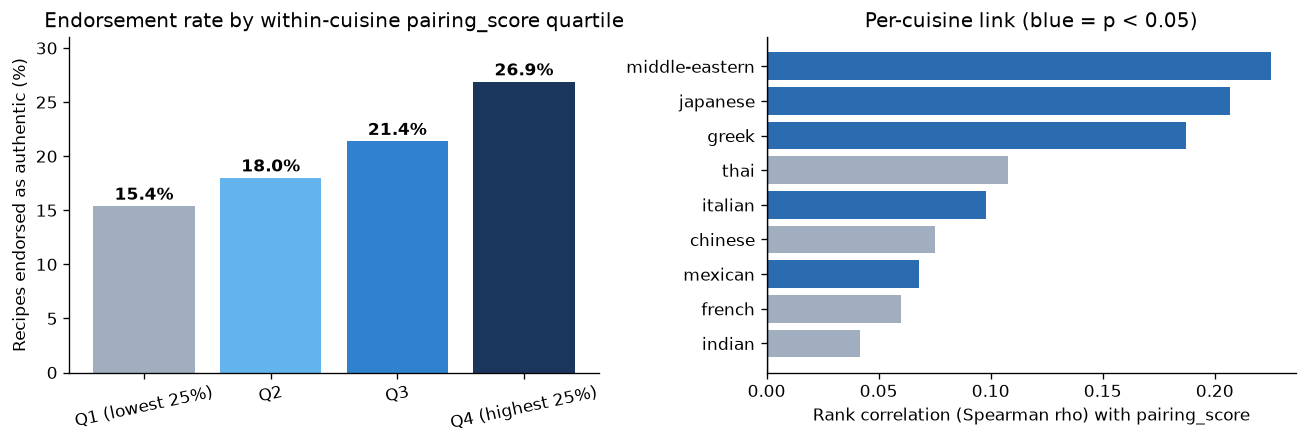

In [6]:
network = pd.read_csv(DATA / "network_recipe_distinctiveness_full.csv")
recipe_preds = pred_reviews.groupby("recipe_id").agg(
    matched_reviews=("review_id", "size"),
    endorsing_reviews=("predicted_endorsement", "sum"),
    max_score=("score", "max"),
).reset_index()
recipe_preds["predicted_endorsement"] = recipe_preds["endorsing_reviews"] > 0

m = (
    network.merge(recipe_preds, on="recipe_id", how="inner")
    .merge(recipes[["recipe_id", "name", "n_ingredients"]], on="recipe_id", how="left")
    .dropna(subset=["pairing_score"])
    .reset_index(drop=True)
)
m["y"] = m["predicted_endorsement"].astype(int)
m["recipe_type"] = m["name"].fillna("").map(classify_title)
m["size_bin"] = pd.cut(m["n_ingredients"], bins=[0, 6, 9, 12, 100], labels=["<=6", "7-9", "10-12", "13+"])
m["pairing_q"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 4, labels=["Q1 (lowest 25%)", "Q2", "Q3", "Q4 (highest 25%)"])
)
m["pairing_d"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
)

q_df = m.groupby("pairing_q", observed=False).agg(
    recipes=("recipe_id", "size"), endorsed=("y", "sum"), endorsement_rate=("y", "mean")
).reset_index()
display(q_df.assign(endorsement_rate=lambda d: d["endorsement_rate"].map("{:.1%}".format)))

d_rates = m.groupby("pairing_d", observed=False)["y"].mean()
print(f"Bottom 10% vs. Top 10% of pairing_score: {d_rates.iloc[0]:.1%} -> {d_rates.iloc[-1]:.1%} "
      f"({d_rates.iloc[-1]/d_rates.iloc[0]:.2f}x higher endorsement rate)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(q_df["pairing_q"], q_df["endorsement_rate"] * 100, color=["#a0aec0", "#63b3ed", "#3182ce", "#1a365d"])
for i, v in enumerate(q_df["endorsement_rate"] * 100):
    ax1.text(i, v + 0.6, f"{v:.1f}%", ha="center", fontweight="bold")
ax1.set_ylim(0, 31)
ax1.set_ylabel("Recipes endorsed as authentic (%)")
ax1.set_title("Endorsement rate by within-cuisine pairing_score quartile")
ax1.tick_params(axis="x", rotation=12)

c_df = pd.DataFrame([
    {"cuisine": c, "n": len(g), "rho": spearmanr(g["y"], g["pairing_score"])[0], "p": spearmanr(g["y"], g["pairing_score"])[1]}
    for c, g in m.groupby("cuisine")
]).sort_values("rho")
ax2.barh(c_df["cuisine"], c_df["rho"], color=["#2b6cb0" if p < 0.05 else "#a0aec0" for p in c_df["p"]])
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_xlabel("Rank correlation (Spearman rho) with pairing_score")
ax2.set_title("Per-cuisine link (blue = p < 0.05)")
plt.tight_layout()
plt.show()

### Chance check: within-cuisine shuffle test (Week 2)

A raw correlation across all 4,275 recipes could be misleading—for instance, if one cuisine simply has both higher `pairing_score` and more authenticity reviews, or if desserts or long recipes behave differently. Following the same Week 2 null-model idea used in `03_network_analysis.ipynb`, we test every result against **2,000 random shuffles**:

1. Keep every recipe's ingredient score fixed.
2. Randomly shuffle the authentic/not-authentic labels *within each cuisine* (so every cuisine keeps its exact number of recipes and endorsements) and recompute the correlation.
3. Repeat 2,000 times to see what correlations look like by pure chance (`null_mean`), then report how many standard deviations above chance the real correlation sits (`z_score`) and how often chance matches it (`empirical_p`).

We run this check on all three ingredient scores from `03_network_analysis.ipynb`, and then test three stricter controls: using the model's continuous score (no yes/no threshold), removing desserts and drinks while shuffling within `cuisine × recipe length`, and finally keeping only savory recipes with **exactly 1 matched review** so popular recipes with many reviews cannot drive the result.

,test,n,obs_rho,null_mean,z_score,empirical_p
0,Single ingredients (ingredient_distinctiveness),4275,0.0166,0.0091,0.54,0.59220
1,Ingredient pairs (pair_distinctiveness),4275,0.0460,0.0122,2.30,0.02199
2,Pairing above chance (pairing_score),4275,0.0903,-0.0100,6.80,0.00050
3,Robustness: continuous score (no cutoff),4275,0.0774,-0.0083,5.84,0.00050
4,"Robustness: excl. sweets/drinks, within cuisine x size",4084,0.0872,-0.0115,6.61,0.00050
5,Robustness: excl. sweets/drinks + exactly 1 review,3072,0.0664,-0.0108,4.60,0.00050


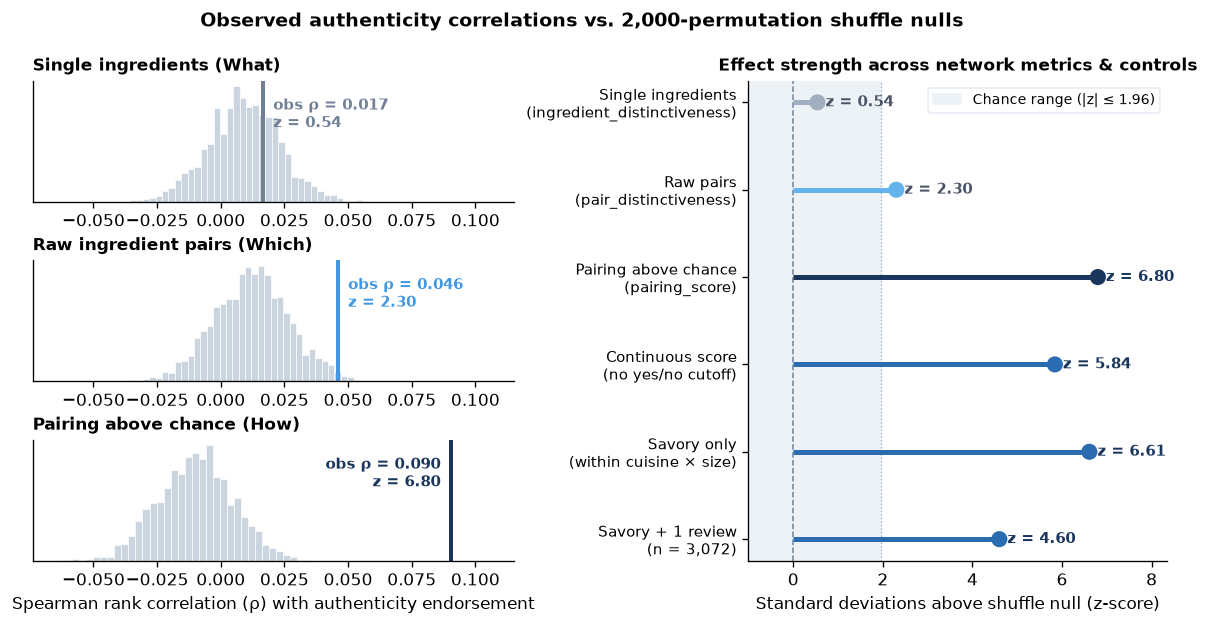

In [7]:
no_sd = m[~m["recipe_type"].isin(["dessert/sweet", "drink"])]
strict = no_sd[no_sd["matched_reviews"] == 1]

tests = [
    ("Single ingredients (ingredient_distinctiveness)", m, "y", "ingredient_distinctiveness", ["cuisine"]),
    ("Ingredient pairs (pair_distinctiveness)", m, "y", "pair_distinctiveness", ["cuisine"]),
    ("Pairing above chance (pairing_score)", m, "y", "pairing_score", ["cuisine"]),
    ("Robustness: continuous score (no cutoff)", m, "max_score", "pairing_score", ["cuisine"]),
    ("Robustness: excl. sweets/drinks, within cuisine x size", no_sd, "y", "pairing_score", ["cuisine", "size_bin"]),
    ("Robustness: excl. sweets/drinks + exactly 1 review", strict, "y", "pairing_score", ["cuisine", "size_bin"]),
]

results = [{"test": lbl, **shuffle_test(sub, yc, xc, st, return_null=True)} for lbl, sub, yc, xc, st in tests]
shuf_table = pd.DataFrame([{k: v for k, v in r.items() if k != "null_dist"} for r in results])
display(shuf_table)

# Visual summary: (A) 2,000-shuffle null distributions for the 3 network scores; (B) z-scores across all 6 tests
fig = plt.figure(figsize=(12.2, 5.2))
gs = fig.add_gridspec(3, 2, width_ratios=[1.15, 1.0], wspace=0.52, hspace=0.48)

short_titles = [
    "Single ingredients (What)",
    "Raw ingredient pairs (Which)",
    "Pairing above chance (How)",
]
line_colors = ["#718096", "#4299e1", "#1a365d"]
x_min = min(r["null_dist"].min() for r in results[:3]) - 0.01
x_max = max(r["obs_rho"] for r in results[:3]) + 0.025

for idx in range(3):
    ax = fig.add_subplot(gs[idx, 0])
    r = results[idx]
    ax.hist(r["null_dist"], bins=36, density=True, color="#cbd5e0", edgecolor="white", linewidth=0.4, label="2,000 within-cuisine shuffles")
    ax.axvline(r["obs_rho"], color=line_colors[idx], linewidth=2.4)
    ax.set_xlim(x_min, x_max)
    ax.set_yticks([])
    ax.set_title(short_titles[idx], loc="left", fontsize=10, fontweight="bold")
    offset = 0.004 if r["obs_rho"] < x_max - 0.045 else -0.004
    ha = "left" if offset > 0 else "right"
    ax.text(
        r["obs_rho"] + offset, ax.get_ylim()[1] * 0.72,
        f"obs ρ = {r['obs_rho']:.3f}\nz = {r['z_score']:.2f}",
        color=line_colors[idx], fontsize=8.8, fontweight="bold", ha=ha, va="center",
    )
    if idx == 2:
        ax.set_xlabel("Spearman rank correlation (ρ) with authenticity endorsement")

ax_z = fig.add_subplot(gs[:, 1])
labels_z = [
    "Single ingredients\n(ingredient_distinctiveness)",
    "Raw pairs\n(pair_distinctiveness)",
    "Pairing above chance\n(pairing_score)",
    "Continuous score\n(no yes/no cutoff)",
    "Savory only\n(within cuisine × size)",
    "Savory + 1 review\n(n = 3,072)",
]
z_vals = [r["z_score"] for r in results]
y_pos = np.arange(len(labels_z))[::-1]
bar_colors = ["#a0aec0", "#63b3ed", "#1a365d", "#2b6cb0", "#2b6cb0", "#2b6cb0"]

ax_z.axvspan(-1.96, 1.96, color="#edf2f7", zorder=0, label="Chance range (|z| ≤ 1.96)")
ax_z.axvline(0, color="#718096", linewidth=0.9, linestyle="--", zorder=1)
ax_z.axvline(1.96, color="#a0aec0", linewidth=0.8, linestyle=":", zorder=1)
ax_z.hlines(y_pos, 0, z_vals, color=bar_colors, linewidth=3.0, zorder=2)
ax_z.scatter(z_vals, y_pos, color=bar_colors, s=75, zorder=3)
for y_i, zv in zip(y_pos, z_vals):
    ax_z.text(zv + 0.18, y_i, f"z = {zv:.2f}", va="center", fontsize=9, fontweight="bold",
              color="#1a365d" if zv >= 4 else "#4a5568")

ax_z.set_yticks(y_pos)
ax_z.set_yticklabels(labels_z, fontsize=8.8)
ax_z.set_xlim(-1.0, max(z_vals) + 1.55)
ax_z.set_xlabel("Standard deviations above shuffle null (z-score)")
ax_z.set_title("Effect strength across network metrics & controls", fontsize=10, fontweight="bold")
ax_z.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#e2e8f0", fontsize=8.4)

fig.suptitle("Observed authenticity correlations vs. 2,000-permutation shuffle nulls", fontsize=11.5, fontweight="bold", y=0.99)
fig.savefig(FIG_DIR / "authenticity_shuffle_nulls.png", dpi=300, bbox_inches="tight")
plt.show()

## Results

**Research question:** *Do the recipes whose ingredients are most typical of their cuisine also get called "authentic" by the people who cook them?*

**Answer: Yes, modestly—and specifically through *how* ingredients are paired rather than *which* single ingredients appear.**

Across **4,275 matched recipes** (7,281 filtered reviews; 873 endorsed recipes, 20.3%), using cuisine-typical single ingredients (`ingredient_distinctiveness`) has no link with being called authentic (ρ = 0.017, shuffle z = 0.54), and raw ingredient pairs (`pair_distinctiveness`) show only a weak link (ρ = 0.046, z = 2.30). By contrast, characteristic ingredient pairing above chance (`pairing_score`) shows a clear positive link (ρ = 0.090, **z = 6.80, p = 0.0005**—not a single one of 2,000 random shuffles reached it):

- **Steady climb across recipes:** endorsement rises from **15.4%** in the lowest quarter of `pairing_score` to **26.9%** in the highest quarter, and **1.87×** from the bottom 10% to the top 10% (**13.9% → 26.0%**).
- **Consistent across cuisines:** all 9 cuisines lean positive, most clearly Middle Eastern, Japanese, Greek, Italian, and Mexican.
- **Holds under stricter checks:** the link stays strong using the continuous model score with no yes/no cutoff (z = 5.84), after removing desserts/drinks and controlling for recipe length (z = 6.61), and even when restricted to savory recipes with exactly 1 matched review (n = 3,072, **z = 4.60, p = 0.0005**).

At the same time, the modest size of the correlation (ρ ≈ 0.09) shows that ingredient pairing is only one piece of perceived authenticity—cooking technique, proportions, personal memories, and Food.com's audience all matter too.

## Biases and limitations

### Biases
- **Food.com audience bias:** Food.com (1999–2018) is mostly North American and English-speaking. *Why it matters:* what feels "authentic" depends on a cook's own background, so our review score reflects *North American home cooks' view of authenticity*, not local culinary history in each cuisine's home country.
- **General-English model bias (`gte-small`):** `gte-small` was trained on general English web text rather than cooking forums. *Why it matters:* it learns everyday English associations around words like *"authentic"* and *"traditional"*, so it can misread brand names (*"Traditional Ragu"*) or restaurant phrasing as recipe praise.
- **Long-review compression:** `gte-small` compresses an entire review into one fixed-size vector before comparing it to each description. *Why it matters:* in long reviews, a brief negation or contrast (*"supposed to be authentic, but..."*) can get washed out—which is why we add clause-level wording flags, though subtle multi-sentence contrasts can still slip through.
- **Review-volume and selection bias:** Only recipes that receive reviews—and reviews using our Stage-1 word list—enter the analysis. *Why it matters:* popular recipes get more reviews and therefore more chances to be praised; our single-review check (n = 3,072, z = 4.60) rules out review count as the cause, but recipes that are never discussed in authenticity terms remain unseen.

### Limitations
- **Missed implicit endorsements:** Reviews that praise authenticity without any Stage-1 word (e.g., *"just like my grandmother made"*) never enter the 7,281-review set. *Why:* Stage 1 requires an authenticity word and a recipe feature in the same sentence so broad words like *"real"* do not pull in conversational filler (*"a real hit"*); we trade some coverage for a clean candidate set.
- **Small test set and single labeler:** Test precision (`16/18`) and recall (`16/22`) are measured on 100 unseen reviews labeled by one person. *Why:* reading and labeling full reviews by hand takes time, so our recall estimate has wider uncertainty and lacks a second labeler to measure agreement on borderline reviews.
- **Denials grouped with neutral mentions:** Reviews that explicitly say *"not authentic"* are grouped into the "not endorsed" class rather than modeled separately. *Why:* explicit denials are too rare in the 100-review training set to train a reliable third class, so our score measures *positive endorsement* rather than positive vs. negative authenticity.
- **Ingredients alone leave out technique and proportions:** Even though `pairing_score` is clearly above chance (z = 6.80), the correlation is modest (ρ = 0.090). *Why:* the recipe–ingredient network only sees *which* ingredients appear together—not amounts, seasoning ratios, or cooking methods—which play a large role in whether a dish tastes authentic.